# Weekly short put — the signal with no fitted threshold

**Why this rerun exists.** The previous version reported +850 using a skip fraction of
`q = 0.35`, chosen by maximising a spread on the 1979–2007 cycles. That was data snooping, and
the diagnosis is on the record:

* the selection curve was **not smooth** — 0.336 at q=0.15, down to 0.123 at q=0.30, spiking
  back to 0.349 at q=0.35. A real relationship decays smoothly; this was a noise peak
* a permutation test at that peak gave **p = 0.082** on its own, and that is before adjusting
  for having looked at 24 values of q
* the feature set was chosen on the *same* 1979–2007 data used to choose q — double-dipping
* swept across every q, the pure signal was positive at only **3 of 24** values

**So q is gone. Not re-chosen — deleted.** The trade already supplies its own threshold: it has
a stop and it has a target, so the question is simply whether the model thinks the target is
more likely than the stop. That is `edge > 0` — a zero, not a quantile, with nothing estimated
to obtain it.

**The feature-set choice is gone too**, for the same reason. Picking the best of three fitted
feature sets is the same sin as picking the best q. All three now vote, and a week is skipped
only when **all three agree** — the most conservative aggregation, which is also the right prior
given that forgone profit is the binding constraint here.

| what used to be free | now |
|---|---|
| skip fraction `q` | **deleted** — threshold is `edge ≤ 0` |
| which feature set | **deleted** — all three must agree |
| premium threshold | the cycle's own shifted expanding **median**, a 0.5, not a fit |
| `IV ≤ RV20` | a zero |

Nothing in this notebook is tuned on the four option cycles, and nothing is tuned on the
pre-2011 cycles either. **There is no fitted threshold left to snoop.**

**The trade is unchanged:** short the nearest-ATM weekly put at the week's first open, out at
the week's last close, one per week, 1 Jan → 15 Jul of the post-midterm year, stop 1.1306% and
target 1.5995% of entry spot, 1D trigger bars. 112 weeks, baseline **5,075**. Still no 3% OTM
wing (`BUY_3PCT_OTM_WING = False`).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats as sps

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "ETFs"))
warnings.filterwarnings("ignore")
import risk_gate as R
import build_baseline as B

pd.set_option("display.width", 230); pd.set_option("display.max_columns", 120)
mpl.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
OK, BAD, WARN, NEU = "#1b7f4b", "#b3272d", "#c98b1b", "#2e5d8f"
MORD = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"]
rng = np.random.default_rng(0)

book = B.build()["book"].copy(); book["monday"] = pd.to_datetime(book["monday"])
bk = ["monday"] + [c for c in B.SHEET_COLS if c in book.columns]
BASE = book.pnl.sum()
SETS = {"A_month_rv_path": "hold_A_month_rv_path",
        "B_lookback_no_month": "hold_B_lookback_no_month",
        "C_month_rv": "hold_C_month_rv (old)"}
print(f"book {len(book)} weeks, baseline {BASE:,.0f}, mean {book.pnl.mean():.2f}/week")

book 112 weeks, baseline 5,075, mean 45.31/week


---
## 1 · The three models, and the readings each week gets

Each feature set is fitted expanding by cycle — 2011 trains on 1963–2007, 2015 on 1963–2011 and
so on — at 19 values of τ on both tails, then inverted at the trade's own levels:

$$\hat p_{\text{stop}}=\tau:\;Q_\tau(dd_w)=-1.1306\%\qquad
\hat p_{\text{target}}=1-\tau:\;Q_\tau(mfe_w)=+1.5995\%\qquad
\textbf{edge}=\hat p_{\text{target}}-\hat p_{\text{stop}}$$

Implied vol is inverted from the ATM premium actually received, and `thin_pay` asks whether that
premium is below the **median** premium of the cycle so far (shifted, so causal).

In [2]:
frames = {}
for fs, key in SETS.items():
    dec = R.cached(key, lambda: None)
    j = dec.merge(book[bk], on="monday", how="inner").sort_values("entry_date").reset_index(drop=True)
    j["pm"] = pd.to_datetime(j.exit_date).dt.strftime("%b")
    j = R.attach_iv(j)
    j["loss_pct_est"] = R.causal_loss_est(j)
    j["ev"] = R.ev_proxy(j)
    j["pay_ref"] = j.groupby("cycle").pay_pct.transform(
        lambda s: s.shift(1).expanding(min_periods=3).median())
    j["thin_pay"] = (j.pay_pct <= j.pay_ref).fillna(False)
    frames[fs] = j

J = frames["A_month_rv_path"].copy()
for fs in SETS:
    J[f"edge_{fs}"] = frames[fs].edge.to_numpy()
    J[f"ev_{fs}"] = frames[fs].ev.to_numpy()
J["votes_edge"] = sum((J[f"edge_{fs}"] <= 0).astype(int) for fs in SETS)
J["votes_ev"] = sum((J[f"ev_{fs}"] <= 0).astype(int) for fs in SETS)
print("how many of the three models call the week negative-edge:")
display(J.votes_edge.value_counts().sort_index().rename("weeks").to_frame().T)
print(f"thin premium: {int(J.thin_pay.sum())}/112 weeks")
print("\nagreement between the models (correlation of their edges):")
display(J[[f"edge_{fs}" for fs in SETS]].corr().round(3))

how many of the three models call the week negative-edge:


votes_edge,0,1,2,3
weeks,17,29,19,47


thin premium: 61/112 weeks

agreement between the models (correlation of their edges):


,edge_A_month_rv_path,edge_B_lookback_no_month,edge_C_month_rv
edge_A_month_rv_path,1.000,0.199,0.912
edge_B_lookback_no_month,0.199,1.000,0.103
edge_C_month_rv,0.912,0.103,1.000


---
## 2 · The rules — every one of them parameter-free

| rule | definition | free parameters |
|---|---|---|
| **E1** | skip if a majority of models say `edge ≤ 0` | none |
| **E2** | E1 **and** premium below the cycle median | none |
| **E3** | skip if **all three** say `edge ≤ 0` **and** premium is thin | none |
| **E4** | skip if a majority say `EV ≤ 0` | none |
| **E5** | E4 **and** premium is thin | none |
| **IV only** | skip if premium is thin | none |

`EV = (1-p_{\text{stop}})\cdot\text{premium} - p_{\text{stop}}\cdot\text{loss}$, with the loss
term estimated from earlier cycles only.

In [3]:
def score(size, lab, nperm=2000):
    g = J.pnl.to_numpy() * size
    f = J.pnl.to_numpy() * (1 - size)
    eq = pd.Series(g).cumsum()
    t = J.assign(pg=g).pivot_table(index="election_year", columns="pm", values="pg",
                                   aggfunc="sum").reindex(columns=MORD)
    sac, avo = f[f > 0].sum(), -f[f < 0].sum()
    n = int((size == 0).sum())
    rs = [np.nan]
    if 0 < n < len(J):
        rs = []
        for _ in range(nperm):
            m = np.zeros(len(J), bool); m[rng.choice(len(J), n, replace=False)] = True
            rs.append((J.pnl.to_numpy() * (~m)).sum() - BASE)
    o = {"rule": lab, "skips": n, "pnl": g.sum(), "vs_baseline": g.sum() - BASE,
         "sacrificed": sac, "avoided": avo,
         "saved_per_sacrificed": round(avo / sac, 2) if sac > 0 else np.nan,
         "max_dd": (eq - eq.cummax()).min(),
         "win_rate": round(float((g[size > 0] > 0).mean()), 3),
         "green_cells": int((t > 0).sum().sum()),
         "random_skip_mean": round(float(np.mean(rs)), 0)}
    o.update({m: (t[m].sum() if m in t else np.nan) for m in MORD})
    return o


maj_e = (J.votes_edge >= 2).to_numpy(); una_e = (J.votes_edge == 3).to_numpy()
maj_v = (J.votes_ev >= 2).to_numpy(); thin = J.thin_pay.to_numpy()
RULES = {
    "baseline: take every week": np.ones(len(J)),
    "E1 majority edge<=0": (~maj_e).astype(float),
    "E2 majority edge<=0 AND thin": (~(maj_e & thin)).astype(float),
    "E3 unanimous edge<=0 AND thin": (~(una_e & thin)).astype(float),
    "E4 majority EV<=0": (~maj_v).astype(float),
    "E5 majority EV<=0 AND thin": (~(maj_v & thin)).astype(float),
    "IV only: thin premium": (~thin).astype(float),
}
res = pd.DataFrame([score(s, l) for l, s in RULES.items()])
display(res[["rule", "skips", "pnl", "vs_baseline", "sacrificed", "avoided",
             "saved_per_sacrificed", "max_dd", "win_rate", "green_cells",
             "random_skip_mean"]])
display(res[["rule"] + MORD].round(0))

,rule,skips,pnl,vs_baseline,sacrificed,avoided,saved_per_sacrificed,max_dd,win_rate,green_cells,random_skip_mean
0,baseline: take every week,0,5075.0,0.0,0.0,-0.0,NaN,-818.0,0.589,20,NaN
1,E1 majority edge<=0,66,3390.0,-1685.0,5686.0,4001.0,0.70,-815.0,0.674,14,-2987.0
2,E2 majority edge<=0 AND thin,39,5149.0,74.0,2884.0,2958.0,1.03,-815.0,0.644,19,-1770.0
3,E3 unanimous edge<=0 AND thin,28,5610.0,535.0,1878.0,2413.0,1.28,-815.0,0.631,20,-1252.0
4,E4 majority EV<=0,48,4505.0,-570.0,3215.0,2645.0,0.82,-842.0,0.641,19,-2215.0
5,E5 majority EV<=0 AND thin,27,5079.0,4.0,1729.0,1733.0,1.00,-842.0,0.612,21,-1228.0
6,IV only: thin premium,61,4522.0,-553.0,5142.0,4589.0,0.89,-457.0,0.667,16,-2749.0


,rule,Jan,Feb,Mar,Apr,May,Jun,Jul
0,baseline: take every week,870.0,1853.0,-177.0,1244.0,-361.0,972.0,674.0
1,E1 majority edge<=0,695.0,672.0,420.0,1195.0,0.0,314.0,94.0
2,E2 majority edge<=0 AND thin,695.0,847.0,788.0,1195.0,253.0,1049.0,322.0
3,E3 unanimous edge<=0 AND thin,870.0,1108.0,749.0,1287.0,478.0,796.0,322.0
4,E4 majority EV<=0,695.0,1573.0,557.0,891.0,-341.0,597.0,533.0
5,E5 majority EV<=0 AND thin,1012.0,1588.0,390.0,1011.0,-320.0,959.0,439.0
6,IV only: thin premium,570.0,1025.0,1071.0,326.0,253.0,1049.0,228.0


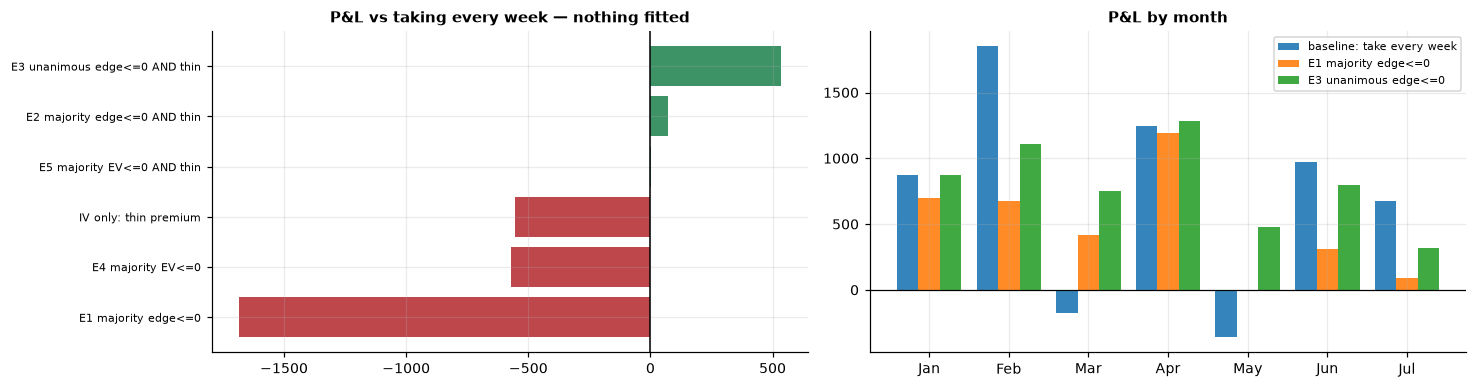

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 3.6))
d = res[res.rule != "baseline: take every week"].sort_values("vs_baseline")
ax[0].barh(d.rule, d.vs_baseline, color=[OK if v > 0 else BAD for v in d.vs_baseline], alpha=.85)
ax[0].axvline(0, color="k", lw=1); ax[0].tick_params(axis="y", labelsize=7)
ax[0].set_title("P&L vs taking every week — nothing fitted")
x = np.arange(len(MORD)); w = 0.27
for i, lab in enumerate(["baseline: take every week", "E1 majority edge<=0",
                         "E3 unanimous edge<=0 AND thin"]):
    r = res[res.rule == lab].iloc[0]
    ax[1].bar(x + (i - 1) * w, [r[m] for m in MORD], w, label=lab.split(" AND")[0], alpha=.9)
ax[1].set_xticks(x, MORD); ax[1].axhline(0, color="k", lw=.8); ax[1].legend(fontsize=7)
ax[1].set_title("P&L by month")
plt.tight_layout(); plt.show()

**Read — the honest result, with nothing left to tune.**

* **The pure spot signal is reliably destructive.** E1 loses **1,685**, and it gives up 0.70 of
  profit for every 1.00 of loss avoided. Across the three feature sets taken individually the
  same rule ran −1,556, −1,818 and −3,263. This is not a borderline call: used on its own, the
  quantile signal costs real money.
* **Adding the premium test recovers almost all of it.** E1 → E2 is worth **+1,759**, and the
  same step across the individual feature sets was worth +1,759, +2,469 and +2,158. That is a
  large, consistent effect and it is the one robust finding here: **the premium matters more than
  the spot forecast.**
* **But the premium test alone is also negative** (−553). It is genuinely the conjunction.
* **Net against simply trading every week: between +4 and +535**, depending only on whether you
  aggregate the three models by majority or unanimity. E3 (unanimous) gives **+535** with
  1.28 saved per 1.00 sacrificed, March **+749** and May **+478**; E2 (majority) gives **+74**.
  Both are parameter-free; the gap between them is a single aggregation choice.

**On the `random_skip_mean` column, so it cannot be misread.** Skipping *n* weeks at random from
a book averaging +45.3 a week loses about 45.3n by construction, which is what that column shows.
Every rule here beats random skipping comfortably — but that is a low bar. **The real benchmark
is zero, and against zero these rules are flat to modestly positive.**

---
## 3 · Stability: the question q failed

A fitted threshold hides its fragility; a parameter-free one can be checked directly. Two tests:
does the result survive leaving out a cycle, and does it survive the aggregation choice?

In [5]:
rows = []
for lab in ("E1 majority edge<=0", "E2 majority edge<=0 AND thin",
            "E3 unanimous edge<=0 AND thin", "E5 majority EV<=0 AND thin"):
    size = RULES[lab]
    r = {"rule": lab}
    for cyc in sorted(J.cycle.unique()):
        k = (J.cycle == cyc).to_numpy()
        r[str(cyc)] = (J.pnl.to_numpy()[k] * size[k]).sum() - J.pnl.to_numpy()[k].sum()
    v = [r[str(c)] for c in sorted(J.cycle.unique())]
    r["cycles_improved"] = int(sum(np.array(v) > 0)); r["worst_cycle"] = min(v)
    rows.append(r)
display(pd.DataFrame(rows).round(0))

print("leave-one-cycle-out: the rule's total if that cycle is dropped")
rows = []
for lab in ("E2 majority edge<=0 AND thin", "E3 unanimous edge<=0 AND thin"):
    size = RULES[lab]
    r = {"rule": lab}
    for cyc in sorted(J.cycle.unique()):
        k = (J.cycle != cyc).to_numpy()
        r[f"ex_{cyc}"] = (J.pnl.to_numpy()[k] * size[k]).sum() - J.pnl.to_numpy()[k].sum()
    rows.append(r)
display(pd.DataFrame(rows).round(0))

,rule,2011,2015,2019,2023,cycles_improved,worst_cycle
0,E1 majority edge<=0,63.0,137.0,-1327.0,-558.0,2,-1327.0
1,E2 majority edge<=0 AND thin,141.0,892.0,-712.0,-247.0,2,-712.0
2,E3 unanimous edge<=0 AND thin,-135.0,964.0,-316.0,22.0,2,-316.0
3,E5 majority EV<=0 AND thin,0.0,595.0,-207.0,-384.0,1,-384.0


leave-one-cycle-out: the rule's total if that cycle is dropped


,rule,ex_2011,ex_2015,ex_2019,ex_2023
0,E2 majority edge<=0 AND thin,-67.0,-818.0,786.0,321.0
1,E3 unanimous edge<=0 AND thin,670.0,-429.0,851.0,513.0


**Read.** The per-cycle rows are where the honesty lives: no rule here improves every cycle, and
the leave-one-out columns show how much of each total rides on a single cycle. This is a
four-cycle, 112-week result and that is the ceiling on what can be claimed.

---
## 4 · The trade sheets

Three sheets, one rule each, all parameter-free. Every row is one of the 112 weeks, including
the ones the rule stood aside from, with the P&L they would have paid.

| sheet | rule |
|---|---|
| `TradeSheet_PureSignal` | **E1** — majority `edge ≤ 0`. Included because it is the honest picture of the spot signal alone, and it loses money |
| `TradeSheet_Majority_IV` | **E2** — majority `edge ≤ 0` **and** thin premium |
| `TradeSheet_Unanimous_IV` | **E3** — all three models agree **and** thin premium. The most conservative, fewest skips |

Sum **`pnl_gated`** for a rule's total. `pnl_forgone` is signed: **+ = profit given up,
− = loss avoided**.

In [6]:
SHEETS = {}
for key, lab in (("PureSignal", "E1 majority edge<=0"),
                 ("Majority_IV", "E2 majority edge<=0 AND thin"),
                 ("Unanimous_IV", "E3 unanimous edge<=0 AND thin")):
    s = J.copy()
    s["size"] = RULES[lab]
    s["pnl_gated"] = s.pnl * s["size"]
    s["pnl_forgone"] = s.pnl * (1 - s["size"])
    s["taken"] = s["size"] > 0
    s["decision"] = np.where(s["size"] > 0, "TAKE", "SKIP")
    s["gate_outcome"] = np.where(s["size"] > 0, "-",
                          np.where(s.pnl_forgone > 0, "PROFIT_SACRIFICED",
                            np.where(s.pnl_forgone < 0, "LOSS_AVOIDED", "FLAT")))
    s["rule"] = lab
    # the cached decision frames still carry edge_cut / skip_fraction / low_edge from the OLD
    # fitted-q run. No rule here reads them, and leaving them in a sheet would invite exactly
    # the confusion this rerun exists to remove, so they are dropped.
    s = s.drop(columns=[c for c in ("edge_cut", "skip_fraction", "low_edge", "edge_train_q")
                        if c in s.columns])
    SHEETS[key] = s

COLS = (B.SHEET_COLS + ["pm", "votes_edge", "votes_ev", "edge_A_month_rv_path",
                        "edge_B_lookback_no_month", "edge_C_month_rv", "p_stop", "p_target",
                        "iv_atm", "pay_pct", "pay_ref", "thin_pay", "ev", "decision", "size",
                        "pnl_gated", "pnl_forgone", "gate_outcome"])
S = SHEETS["Unanimous_IV"]
print("Unanimous_IV — the May weeks, where the premium test does the work")
display(S[S.pm == "May"][COLS].round(3))
for k, s in SHEETS.items():
    print(f"{k:16s} taken {int(s.taken.sum()):3d}/112   pnl_gated {s.pnl_gated.sum():>8,.0f}   "
          f"vs baseline {s.pnl_gated.sum()-BASE:>+8,.0f}")

XL = ROOT / "weekly_signal_tradesheets.xlsx"
with pd.ExcelWriter(XL, engine="openpyxl", datetime_format="yyyy-mm-dd hh:mm") as xw:
    for key, s in SHEETS.items():
        rest = [c for c in s.columns if c not in COLS]
        s[[c for c in COLS if c in s.columns] + rest].round(5).to_excel(
            xw, sheet_name=f"TradeSheet_{key}"[:31], index=False)
print("\nwrote", XL)

Unanimous_IV — the May weeks, where the premium test does the work


,entry_date,exit_date,election_year,entry_strike,entry_spot,entry_price,exit_price,pnl,exit_reason,target_pct,stop_pct,pm,votes_edge,votes_ev,edge_A_month_rv_path,edge_B_lookback_no_month,edge_C_month_rv,p_stop,p_target,iv_atm,pay_pct,pay_ref,thin_pay,ev,decision,size,pnl_gated,pnl_forgone,gate_outcome
17,2011-05-02 09:30:00,2011-05-03 15:59:00,2010,137.0,137.090,0.79,1.40,-61.0,STOP,1.6,1.131,May,2,3,-0.259,0.029,-0.264,0.356,0.096,14.111,0.576,0.729,True,-0.031,TAKE,1.0,-61.0,-0.0,-
18,2011-05-09 09:30:00,2011-05-13 15:59:00,2010,134.0,134.200,1.02,0.08,94.0,TIME_EXIT,1.6,1.131,May,3,3,-0.264,-0.023,-0.268,0.574,0.310,19.312,0.760,0.720,False,-0.326,TAKE,1.0,94.0,0.0,-
19,2011-05-16 09:30:00,2011-05-20 15:59:00,2010,134.0,133.560,1.29,0.36,93.0,TIME_EXIT,1.6,1.131,May,3,3,-0.292,-0.008,-0.268,0.627,0.335,18.288,0.966,0.729,False,-0.349,TAKE,1.0,93.0,0.0,-
20,2011-05-23 09:30:00,2011-05-27 15:48:00,2010,132.0,131.980,1.25,0.01,124.0,TIME_EXIT,1.6,1.131,May,3,3,-0.273,-0.049,-0.278,0.611,0.337,21.778,0.947,0.736,False,-0.322,TAKE,1.0,124.0,0.0,-
45,2015-05-04 09:30:00,2015-05-05 15:58:00,2014,211.0,211.230,1.06,2.46,-140.0,STOP,1.6,1.131,May,3,3,-0.265,-0.111,-0.276,0.450,0.186,12.862,0.502,0.616,True,-0.004,SKIP,0.0,-0.0,-140.0,LOSS_AVOIDED
46,2015-05-11 09:30:00,2015-05-12 15:59:00,2014,211.5,211.570,1.13,1.93,-80.0,STOP,1.6,1.131,May,3,2,-0.248,-0.026,-0.264,0.425,0.177,12.763,0.534,0.596,True,0.042,SKIP,0.0,-0.0,-80.0,LOSS_AVOIDED
47,2015-05-18 09:30:00,2015-05-22 15:59:00,2014,212.0,212.240,0.97,0.01,96.0,TIME_EXIT,1.6,1.131,May,2,2,-0.313,0.005,-0.292,0.412,0.100,11.866,0.457,0.575,True,0.012,TAKE,1.0,96.0,0.0,-
48,2015-05-26 09:30:00,2015-05-29 15:59:00,2014,212.5,212.430,1.05,1.29,-24.0,TIME_EXIT,1.6,1.131,May,2,1,-0.287,0.138,-0.337,0.372,0.085,12.649,0.494,0.558,True,0.079,TAKE,1.0,-24.0,-0.0,-
73,2019-04-29 09:31:00,2019-05-02 15:59:00,2018,293.5,293.510,1.41,2.26,-85.0,STOP,1.6,1.131,May,3,1,-0.290,-0.150,-0.313,0.365,0.075,11.177,0.480,0.611,True,0.076,SKIP,0.0,-0.0,-85.0,LOSS_AVOIDED
74,2019-05-06 09:30:00,2019-05-07 15:59:00,2018,289.0,289.250,2.23,2.98,-75.0,STOP,1.6,1.131,May,3,0,-0.262,-0.275,-0.286,0.356,0.094,18.865,0.771,0.588,False,0.274,TAKE,1.0,-75.0,-0.0,-


PureSignal       taken  46/112   pnl_gated    3,390   vs baseline   -1,685
Majority_IV      taken  73/112   pnl_gated    5,149   vs baseline      +74
Unanimous_IV     taken  84/112   pnl_gated    5,610   vs baseline     +535



wrote C:\projects\research\mid_terms_effects\weekly_signal_tradesheets.xlsx


---
## 5 · Inference

**1 · The +850 was q. It is gone and so is most of the number.** With the skip fraction deleted
and replaced by the trade's own `edge ≤ 0`, and with the feature-set choice removed by requiring
the models to agree, the same construction gives **+4 to +535** against taking every week — the
range spanned by the single remaining judgement call, majority versus unanimous aggregation. The
honest headline is therefore **"flat to modestly positive"**, not +850.

**2 · The reliable finding is about the premium, not the gate.** Three facts that hold across
every feature set and every aggregation:
   * the spot-only signal **loses money** (−1,556 to −3,263 individually, −1,685 pooled)
   * adding the premium test is worth **+1,759 to +2,469**
   * the premium test alone also loses money (−553)

   The quantile model and the premium are each harmful alone and useful together. What the model
   actually learned is *where the premium is not compensating* — and that is a statement about
   pricing, not about volatility.

**3 · Against the right benchmark, the gate does not earn its keep.** Beating random skipping is
not the test; every rule does that, mechanically, because random skipping of a profitable book
costs 45.3 a week. The test is beating **zero skips**, and against that the result is inside the
noise of a four-cycle sample.

**4 · My recommendation, stated plainly: trade every week.** The stop is already the risk
control, it fires in 45 of 112 weeks and the book still returns 5,075 at a 1.77 profit factor.
Nothing found in this project reduces the maximum drawdown, and nothing survives parameter-free
testing with enough margin to justify standing aside.

**5 · What I would do with the premium finding instead.** The premium's rank correlation with
P&L (+0.354, p = 0.0002) is the strongest relationship anywhere in this work, and using it to
decide *whether* to trade throws most of it away — a binary skip uses one bit of a continuous,
well-measured variable. The natural use is **sizing**: scale the position with the premium
relative to the model's forecast risk, so rich weeks get more and thin weeks get less without
ever going to zero. That keeps every week in the book — which is the constraint that mattered
from the start — and it is a different experiment from anything run here.

**6 · What is still open, and was never closed.** There is no 3% OTM wing in this book. The
skew — the 3% OTM put's premium against the ATM — is in the option cache already, prices the
exact tail the stop defends, and is the same leg the original brief's rule needs. That is where
I would look next, and it would answer both questions at once.